# Simulera flytt till ISK

In [136]:
from dataclasses import asdict, dataclass
import datetime
import matplotlib as mpl
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [137]:
DEPOT_MARKET_VALUE = 1043758
DEPOT_COST_BASIS = 1043758 - 724649
ISK_MARKET_VALUE = 558884

TODAY = datetime.datetime.now().date()
COLORS = mpl.rcParams["axes.prop_cycle"].by_key()["color"]

In [138]:
def step_one_month(dt: datetime) -> datetime:
    """Increment datetime to the first day of the next month."""
    year = dt.year + (dt.month // 12)
    month = 1 if dt.month == 12 else dt.month + 1
    return dt.replace(year=year, month=month, day=1)

def get_monthly_return(annual_gross_return, annual_std, size: int|tuple = 1):
    """Sample monthly returns based on the annually normally distributed return."""
    log_var_a = np.log(1 + (annual_std / annual_gross_return)**2 )
    log_mu_a = np.log(annual_gross_return) - 0.5 * log_var_a

    log_var_m = log_var_a / 12
    log_mu_m = log_mu_a / 12

    Xm = np.random.normal(loc=log_mu_m, scale=log_var_m**0.5, size=size)
    Rm = np.exp(Xm)
    if len(Rm) == 1:
        Rm = Rm[0].item()
    return Rm

In [139]:
@dataclass
class Record:
    value: int
    date: datetime.date
    event: str
    monthly_return: float|None = None
    tax: int|None = None
    value_after_tax: int|None=None


def records_to_df(records: list[Record]) -> pd.DataFrame:
    df = pd.DataFrame.from_records(asdict(r) for r in records)
    df["date"] = pd.to_datetime(df["date"])
    return df

# Definiera kontoklasserna

In [140]:
class FondKonto:

    def __init__(
            self,
            start_date: datetime.datetime,
            start_capital: int,
            annual_return: float,
            annual_std: float,
            cost_basis: int|None = None,
        ):
        self.start_date = start_date if isinstance(start_date, datetime.date) else start_date.date()
        self.acquisition_cost = start_capital
        self.value = start_capital
        if cost_basis is None:
            self.cost_basis = start_capital
        else:
            self.cost_basis = cost_basis
        self.date = start_date
        self.annual_return = annual_return
        self.annual_std = annual_std
        self.records = []

        net_value = self.calc_current_net_value()
        self._update_record(
            value=self.value, date=self.date, event="init", tax=0, value_after_tax=net_value,
        )

    def __repr__(self):
        return f"<FondKonto value={self.value}, date={self.date}, cost_basis={self.cost_basis}>"
    
    @property
    def cost_basis(self):
        return self._cost_basis
    
    @cost_basis.setter
    def cost_basis(self, value: int):
        if (value > self.acquisition_cost) | (value < 0):
            raise ValueError(
                "The cost_basis must be greater than zero and lower than the acquisition cost."
            )
        elif not isinstance(value, int):
            raise TypeError("Cost basis must be an integer.")
        self._cost_basis = value


    def step(self, sell_fraction: float|None = None):
        r = get_monthly_return(
            annual_gross_return=self.annual_return,
            annual_std=self.annual_std,
            size=1,
        )

        self.value = int(self.value * r)
        self.date = step_one_month(self.date)
        if sell_fraction is not None:
            cash, tax = self.sell(fraction=sell_fraction)
        else:
            cash, tax = 0, 0
        net_value = self.calc_current_net_value()
        self._update_record(
            value=self.value, date=self.date, monthly_return=r, event="step", tax=tax, value_after_tax=net_value,
        )
        return self.value, cash

    def sell(self, fraction: float = 1):
        value_to_sell = round(self.value * fraction)
        taxable_profit = fraction * max(0, self.value - self.cost_basis)
        tax = int(0.3 * taxable_profit)
        cash = value_to_sell - tax
        self.value = max(0, self.value - value_to_sell)
        self.cost_basis = round((1 - fraction) * self.cost_basis)
        return cash, tax
    
    def calc_current_net_value(self):
        profit = self.value - self.cost_basis
        tax = 0.3 * max(0, profit)
        return self.value - tax

    def _update_record(self, **kwargs):
        new_record = Record(**kwargs)
        self.records.append(new_record)

In [141]:
class Isk:

    def __init__(
            self,
            start_date: datetime.datetime,
            start_capital: int,
            annual_return: float,
            annual_std: float,
            state_interest_rate: float = 0.0255,
            pay_tax_separately: bool = True,
        ):
        self.start_date = start_date if isinstance(start_date, datetime.date) else start_date.date()
        self.value = start_capital
        self.date = start_date
        self.current_year_deposits = 0
        self.taxable_value = 0
        self.annual_return = annual_return
        self.annual_std = annual_std
        self.state_interest_rate = state_interest_rate
        self.pay_tax_separately = pay_tax_separately
        self.records = []
        self._update_record(value=self.value, date=self.date, event="init")

    def __repr__(self):
        return (
            f"<Isk value={self.value}, date={self.date}, "
            f"current_year_deposits={self.current_year_deposits}, "
            f"taxable_value={self.taxable_value}>"
        )

    def step(self, deposit: int = 0):
        r = get_monthly_return(
            annual_gross_return=self.annual_return,
            annual_std=self.annual_std,
            size=1,
        )

        self.value = int(self.value * r)
        self._deposit(value=deposit)
        self.date = step_one_month(self.date)
        tax = self._update_tax()
        self._update_record(value=self.value, date=self.date, monthly_return=r, event="step", tax=tax)
        return self.value

    def _deposit(self, value: int):
        self.value += value
        self.current_year_deposits += value
    
    def _update_tax(self):
        month = self.date.month
        tax = 0
        if month in (4, 7, 10):
            self.taxable_value += self.value
        elif month == 1:
            self.taxable_value += self.value
            capital_profit =  (self.taxable_value + self.current_year_deposits) / 4
            capital_base = max(0, capital_profit - 300000)
            tax = round(0.3 * (0.01 + self.state_interest_rate) * capital_base)
            self.taxable_value = 0
            self.current_year_deposits = 0
            if not self.pay_tax_separately:
                self.value -= tax
        return tax

    def _update_record(self, **kwargs):
        new_record = Record(**kwargs)
        self.records.append(new_record)

# Skapa scenariosimulatorerna

**Scenarion**
- Sell-now: Sälj fonderna på depån idag och investera resterande belopp efter vinstskatt i ISK.
- Sell-later: Sälj fonderna på depån senare.

In [142]:
def _to_monthly_deposit_array(monthly_deposit: int | np.ndarray, n_years: int) -> np.ndarray:
    n_months = n_years * 12
    if isinstance(monthly_deposit, int):
        return np.full(n_months, monthly_deposit, dtype=int)

    monthly_deposit = np.asarray(monthly_deposit, dtype=int)
    if monthly_deposit.shape[0] != n_months:
        raise ValueError(f"monthly_deposit must have length {n_months}.")
    return monthly_deposit


def sell_depot_now(
        n_years: int,
        fk_ar: float,
        fk_std: float,
        isk_ar: float,
        isk_std: float,
        monthly_deposit: int|np.ndarray,
        pay_isk_tax_separately: bool = False,
    ) -> tuple[np.ndarray, np.ndarray]:

    start_date = datetime.date(2026, 1, 1)
    monthly_deposit = _to_monthly_deposit_array(monthly_deposit, n_years)

    fk = FondKonto(
        start_date=start_date,
        start_capital=DEPOT_MARKET_VALUE,
        cost_basis=DEPOT_COST_BASIS,
        annual_return=fk_ar,
        annual_std=fk_std,
    )
    cash, _ = fk.sell(fraction=1)

    isk = Isk(
        start_date=start_date,
        start_capital=ISK_MARKET_VALUE + cash,
        annual_return=isk_ar,
        annual_std=isk_std,
        pay_tax_separately=pay_isk_tax_separately,
    )

    for i in range(12 * n_years - 1):
        isk.step(deposit=monthly_deposit[i])
    isk.step(deposit=monthly_deposit[i+1])  # Run an extra time to align with the other scenario

    df = (
        records_to_df(isk.records)
        .assign(net_value=lambda x: x["value"] - x["tax"].fillna(0).cumsum().astype(int))
        .loc[:, ["date", "net_value"]]
    )

    df = records_to_df(isk.records)
    if pay_isk_tax_separately:
        net_value = df["value"] - df["tax"].fillna(0).astype(int).cumsum()
    else:
        net_value = df["value"]
    
    return df["date"].values, net_value.values

In [143]:
def sell_depot_later(
        n_years: int,
        fk_ar: float,
        fk_std: float,
        isk_ar: float,
        isk_std: float,
        monthly_deposit: int|np.ndarray,
        pay_isk_tax_separately: bool = False,
    ) -> tuple[np.ndarray, np.ndarray]:

    start_date = datetime.date(2026, 1, 1)
    monthly_deposit = _to_monthly_deposit_array(monthly_deposit, n_years)

    fk = FondKonto(
        start_date=start_date,
        start_capital=DEPOT_MARKET_VALUE,
        cost_basis=DEPOT_COST_BASIS,
        annual_return=fk_ar,
        annual_std=fk_std,
    )

    isk = Isk(
        start_date=start_date,
        start_capital=ISK_MARKET_VALUE,
        annual_return=isk_ar,
        annual_std=isk_std,
        pay_tax_separately=pay_isk_tax_separately,
    )

    for i in range(12 * n_years - 1):
        isk.step(deposit=monthly_deposit[i])
        fk.step()

    _, cash = fk.step(sell_fraction=1)
    isk.step(deposit=monthly_deposit[i+1] + cash)
    df_isk = records_to_df(isk.records).set_index("date")
    df_fk = records_to_df(fk.records).set_index("date")
    if pay_isk_tax_separately:
        isk_tax = df_isk["tax"].fillna(0).astype(int).cumsum()
        values = (df_isk["value"] + df_fk["value_after_tax"] - isk_tax).values
    else:
        values = (df_isk["value"] + df_fk["value_after_tax"]).values
    dt = df_isk.index.to_numpy()
    return dt, values

In [144]:
def simulate(fn, samples, **kwargs):
    """Helper tp run the Monte Carlo simulation of a scenario."""
    net_values = []
    for _ in range(samples):
        dt, net_value = fn(**kwargs)
        net_values.append(net_value.reshape(1, -1))
    net_values = np.vstack(net_values)
    return dt, net_values

# Simulera med Monte-Carlo

In [145]:
n_years = 40
fk_ar = 1.08
fk_std = 0.07
isk_ar = 1.3
isk_std = 0.08
monthly_deposit = 2000
samples = 1000
pay_isk_tax_separately = False

dt_now, net_values_now = simulate(
    sell_depot_now,
    samples=samples,
    n_years=n_years,
    fk_ar=fk_ar,
    fk_std=fk_std,
    isk_ar=isk_ar,
    isk_std=isk_std,
    monthly_deposit=monthly_deposit,
    pay_isk_tax_separately=pay_isk_tax_separately,
)

In [146]:
dt_later, net_values_later = simulate(
    sell_depot_later,
    samples=samples,
    n_years=n_years,
    fk_ar=fk_ar,
    fk_std=fk_std,
    isk_ar=isk_ar,
    isk_std=isk_std,
    monthly_deposit=monthly_deposit,
    pay_isk_tax_separately=pay_isk_tax_separately,
)

# Resultat

### Monte-Carlo paths

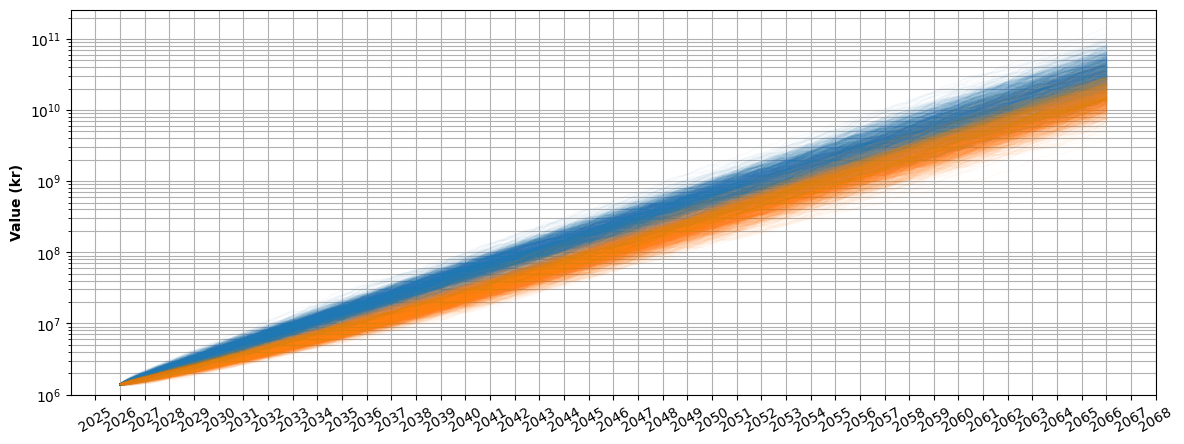

In [147]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.semilogy(dt_now, net_values_now.T, color=COLORS[0], alpha=0.03, linewidth=1, zorder=3)
ax.semilogy(dt_later, net_values_later.T, color=COLORS[1], alpha=0.03, linewidth=1, zorder=4)
ax.grid(zorder=1, which="both")
ax.set_ylabel("Value (kr)", fontweight="bold")
ax.set_ylim(1e6, None)
ax.xaxis.set_major_locator(mdates.YearLocator(base=1))
ax.tick_params(axis="x", rotation=30)
plt.show()

### Medelavkastning med 95 % utfallsintervall

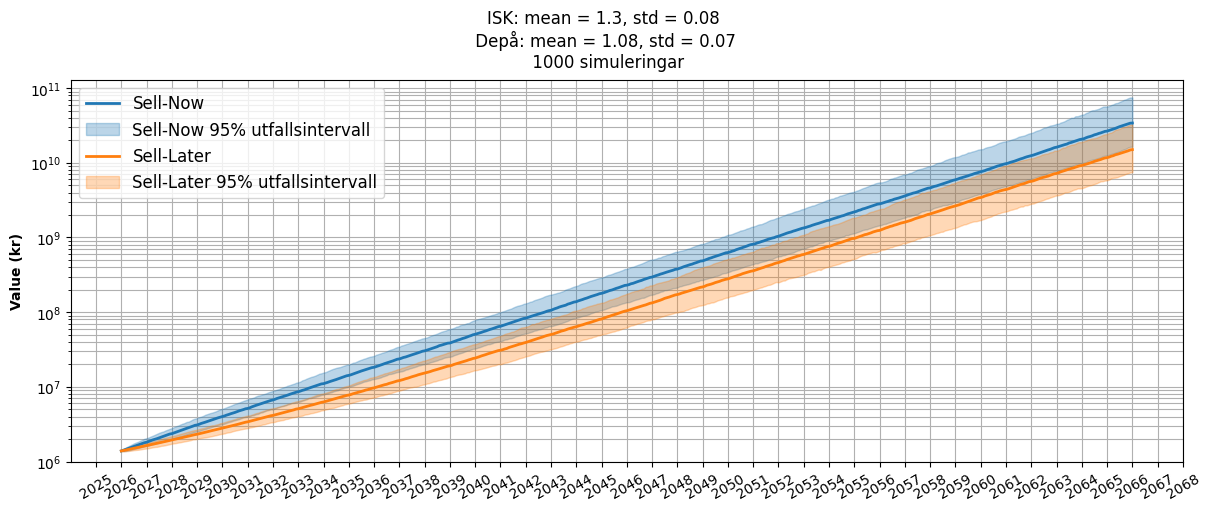

In [148]:
fig, ax = plt.subplots(figsize=(12, 5), layout="constrained")
fig.suptitle(f"ISK: mean = {isk_ar}, std = {isk_std} \n Depå: mean = {fk_ar}, std = {fk_std} \n {samples} simuleringar", fontsize=12)
for i, (label, arr, dt) in enumerate([
    ["Sell-Now", net_values_now, dt_now],
    ["Sell-Later", net_values_later, dt_later],
]):
    q_low, q_high = np.quantile(arr, (0.025, 0.975), axis=0)
    mean = arr.mean(axis=0)
    median = np.median(arr, axis=0)
    ax.semilogy(dt, median, color=COLORS[i], linewidth=2, label=label, zorder=3)
    ax.fill_between(dt, q_low, q_high, alpha=0.3, color=COLORS[i], label=f"{label} 95% utfallsintervall", zorder=2)
ax.grid(zorder=1, which="both")
ax.set_ylabel("Value (kr)", fontweight="bold")
ax.set_ylim(1*1e6, None)

ax.legend(fontsize=12)
ax.xaxis.set_major_locator(mdates.YearLocator(base=1))
ax.tick_params(axis="x", rotation=30)

plt.show()

### Sannolikhet att Sell-Now vinner över Sell-Later

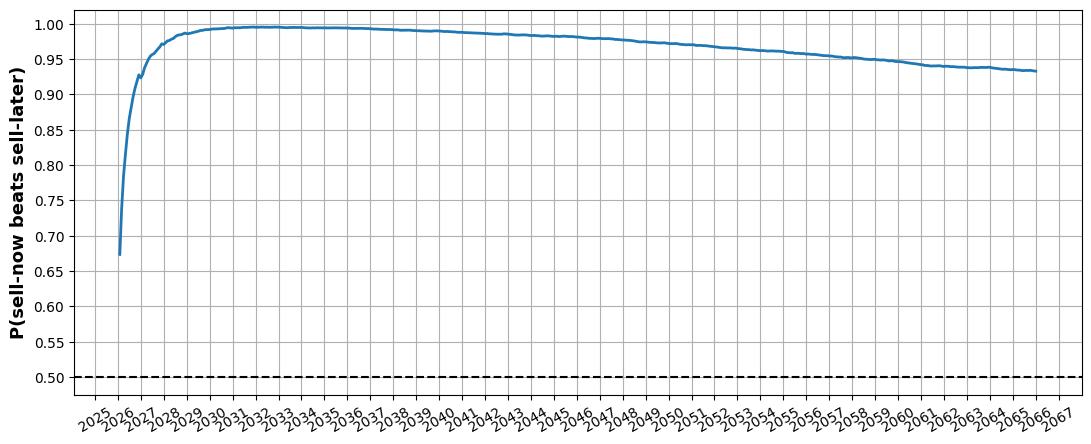

In [149]:
prob = (
    np.mean(net_values_now[:, None, :] > net_values_later[None, :, :], axis=(0, 1))
    + 0.5 * np.mean(net_values_now[:, None, :] == net_values_later[None, :, :], axis=(0, 1))
)


fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(dt_now[1:], prob[1:], linewidth=2, zorder=3)
ax.grid(zorder=1)
ax.axhline(0.5, color="k", linestyle="--", zorder=2)
ax.xaxis.set_major_locator(mdates.YearLocator(base=1))
ax.tick_params(axis="x", rotation=30)
ylow, yhigh = ax.get_ylim()
ax.set_yticks(np.arange(0, 1.01, 0.05))
ax.set_ylim(ylow, yhigh)
ax.set_ylabel("P(sell-now beats sell-later)", fontweight="bold", fontsize=13)
plt.show()

### Fördelning av scenarion vid sluttiden

Mean sell-now:   37127.325 mkr
Mean sell-later: 16356.196 mkr


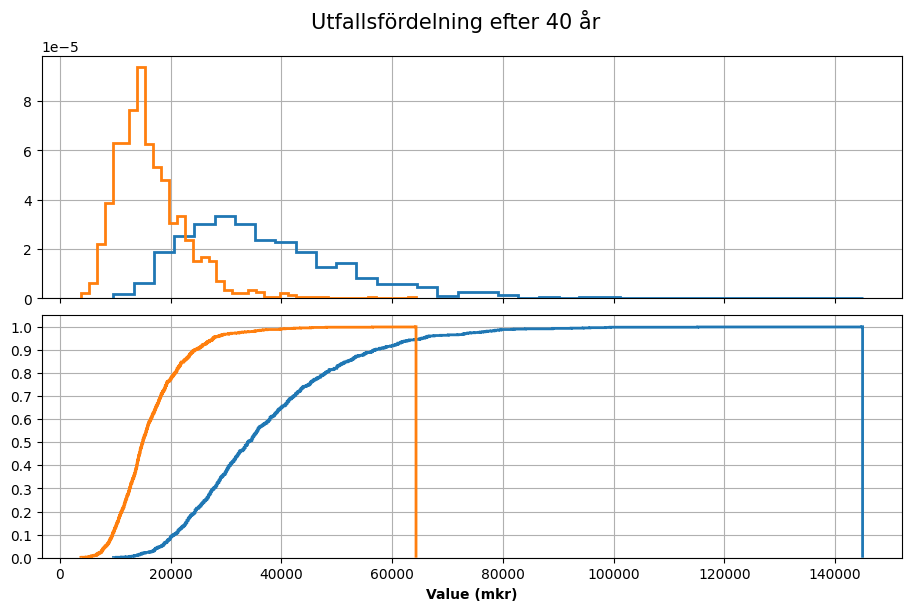

In [150]:
mean_now = (net_values_now[:, -1].mean() * 1e-6).round(3).item()
mean_later = (net_values_later[:, -1].mean() * 1e-6).round(3).item()
print(f"Mean sell-now:   {mean_now} mkr")
print(f"Mean sell-later: {mean_later} mkr")

fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True, layout="constrained")
fig.suptitle(f"Utfallsfördelning efter {n_years} år", fontsize=15)
for ax, cumulative in zip(axes, [False, True]):
    for arr in [net_values_now[:,-1], net_values_later[:,-1]]:
        ax.hist(
            arr*1e-6,
            bins=1000 if cumulative else "auto",
            histtype="step",
            linewidth=2,
            density=True,
            cumulative=cumulative,
            zorder=3,
        )
    ax.grid(zorder=1)
    if cumulative:
        ax.set_yticks(np.arange(0, 1.01, 0.1))
ax.set_xlabel("Value (mkr)", fontweight="bold")

plt.show()

In [151]:
median_now = (np.median(net_values_now[:, -1]) * 1e-6).round(3).item()
median_later = (np.median(net_values_later[:, -1]) * 1e-6).round(3).item()
print(f"Median sell-now:   {median_now} mkr")
print(f"Median sell-later: {median_later} mkr")
print(f"Medianfördel sell-now: {round(median_now - median_later, 2)} kr")

Median sell-now:   34069.252 mkr
Median sell-later: 15010.387 mkr
Medianfördel sell-now: 19058.86 kr
